# Classification Algorithms Comparison

## Objective
The objective of this project is to compare three classification algorithms:
1. Decision Tree
2. Random Forest
3. Support Vector Machine (SVM)

The models will be trained on the same dataset and evaluated using
accuracy, precision, recall, F1-score, confusion matrix, and training time.

In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    make_scorer
)

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


## 1. Dataset Loading

We are using the Breast Cancer Wisconsin dataset from Scikit-learn.
It contains 569 records and 30 numerical features.
The target has two classes: Malignant and Benign.

In [2]:

# Step 2: Load Dataset

cancer = load_breast_cancer()

X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

y = pd.Series(cancer.target, name="target")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(cancer.target_names)


Dataset Loaded Successfully!
Dataset Shape: (569, 30)
Target Shape: (569,)

Target Classes:
['malignant' 'benign']


## 2. Dataset Exploration

In [3]:

# Step 3: Explore Dataset

print("First 5 Rows:")
display(X.head())

print("\nDataset Information:")
X.info()

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nClass Distribution:")
print(y.value_counts())


First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoo

## 3. Splitting Dataset into Training and Testing Sets

The dataset is divided into 80% training data and 20% testing data.
The same train-test split is used for all three classification models.

In [4]:

# Step 4: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)
Training Target Shape: (455,)
Testing Target Shape: (114,)


## 4. Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm
that uses decision rules to classify data.

We use GridSearchCV to find the best hyperparameters.

In [5]:

# Step 5: Decision Tree Hyperparameter Tuning

dt = DecisionTreeClassifier(random_state=42)

dt_params = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]
}

malignant_f1 = make_scorer(f1_score, pos_label=0)

dt_grid = GridSearchCV(
    dt,
    dt_params,
    cv=5,
    scoring=malignant_f1,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)

print("\nBest Cross Validation Score:")
print(dt_grid.best_score_)


Best Decision Tree Parameters:
{'max_depth': 5, 'min_samples_split': 5}

Best Cross Validation Score:
0.9148953375559475


## 5. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines
multiple decision trees to improve classification performance.

GridSearchCV is used to tune its hyperparameters.

In [6]:

# Step 6: Random Forest Hyperparameter Tuning

rf = RandomForestClassifier(random_state=42)

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring=malignant_f1,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross Validation Score:")
print(rf_grid.best_score_)


Best Random Forest Parameters:
{'max_depth': 10, 'n_estimators': 200}

Best Cross Validation Score:
0.9469344254621787


## 6. Support Vector Machine (SVM)

SVM is a supervised learning algorithm that finds
an optimal decision boundary between different classes.

StandardScaler is used because SVM is sensitive to feature scales.

In [7]:

# Step 7: SVM Hyperparameter Tuning

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

svm_params = {
    'svm__C': [0.1, 1, 10],
    'svm__kernel': ['linear', 'rbf'],
    'svm__gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring=malignant_f1,
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:")
print(svm_grid.best_params_)

print("\nBest Cross Validation Score:")
print(svm_grid.best_score_)


Best SVM Parameters:
{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'linear'}

Best Cross Validation Score:
0.9696760761410339


## 7. Model Evaluation

All three tuned models are evaluated on the same test dataset.

The evaluation metrics include:
- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix
- Training Time

In [8]:

# Step 8: Evaluate All Three Models

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "SVM": svm_grid.best_estimator_
}

results = []
confusion_matrices = {}

for name, model in models.items():

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=0
    )

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    confusion_matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (seconds)": training_time
    })

    print("\n", name)
    print("Confusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=cancer.target_names
    ))

comparison_df = pd.DataFrame(results)

print("\nFinal Comparison Table:")
display(comparison_df.round(4))



 Decision Tree
Confusion Matrix:
[[39  3]
 [ 6 66]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


 Random Forest
Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


 SVM
Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign    

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (seconds)
0,Decision Tree,0.9211,0.8667,0.9286,0.8966,0.0240
1,Random Forest,0.9561,0.9512,0.9286,0.9398,1.1206
2,SVM,0.9825,0.9762,0.9762,0.9762,0.0150


## 8. Confusion Matrix Visualization

Confusion matrices are used to compare the actual and predicted
classifications of all three models.

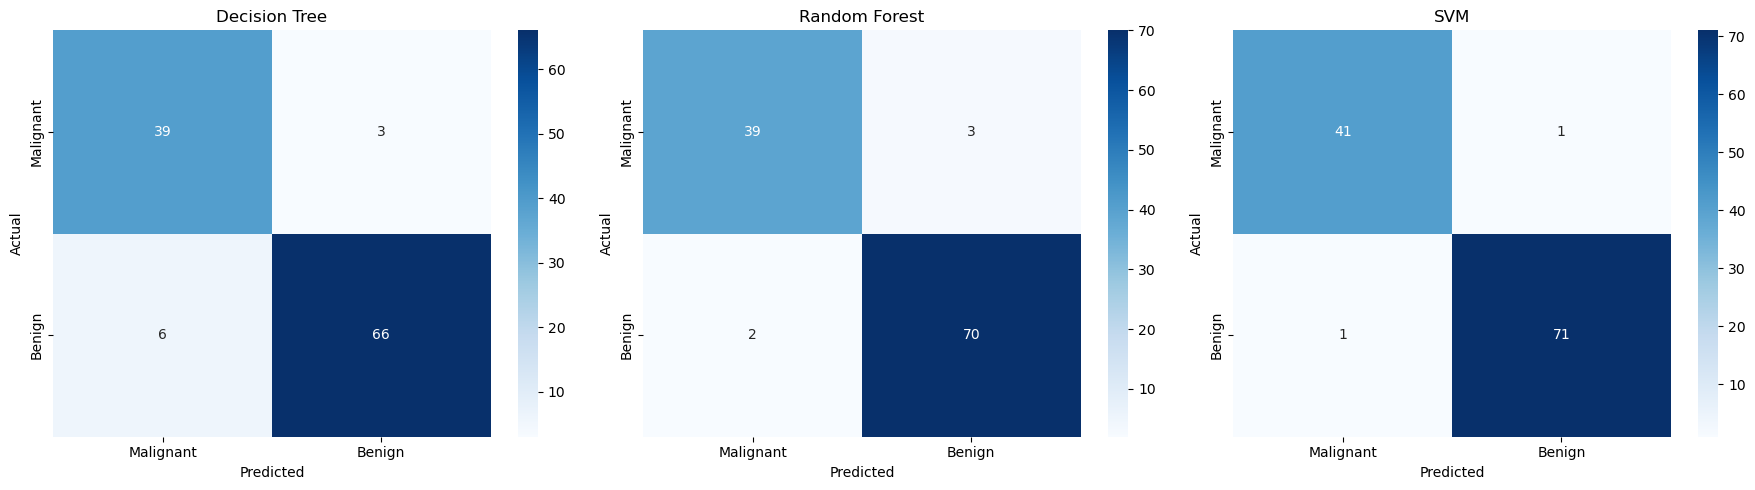

In [9]:

# Step 9: Plot Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, cm) in zip(axes, confusion_matrices.items()):

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Malignant', 'Benign'],
        yticklabels=['Malignant', 'Benign']
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 9. Training Time Comparison

Training time is compared to understand the computational
efficiency of each classification algorithm.

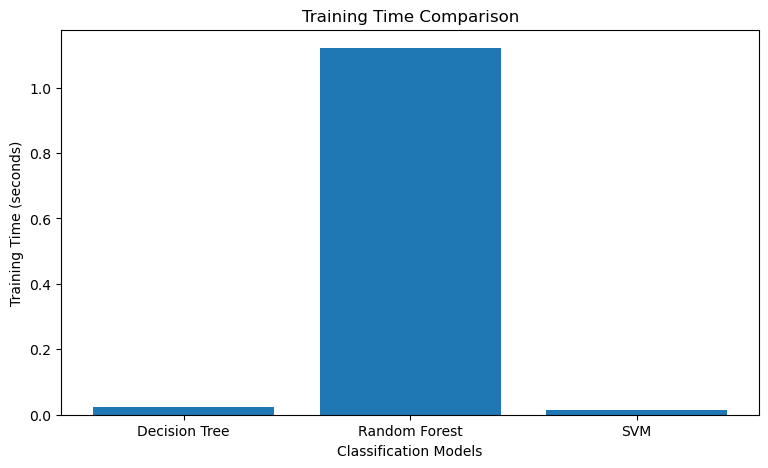

In [10]:

# Step 10: Training Time Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Training Time (seconds)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Training Time (seconds)")

plt.show()


## 10. Final Model Comparison

In [11]:

# Step 11: Final Comparison Table

display(
    comparison_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (seconds)
2,SVM,0.9825,0.9762,0.9762,0.9762,0.0150
1,Random Forest,0.9561,0.9512,0.9286,0.9398,1.1206
0,Decision Tree,0.9211,0.8667,0.9286,0.8966,0.0240


## 11. Performance Analysis

### Decision Tree
Decision Tree uses rule-based splitting to classify data.
It is easy to understand and interpret. However, a single
decision tree may overfit the training data.

### Random Forest
Random Forest combines multiple decision trees to improve
prediction performance. It can reduce overfitting and
provide stable predictions.

### Support Vector Machine
SVM finds an optimal decision boundary between classes.
Feature scaling is important for SVM. The RBF kernel can
capture non-linear patterns in the dataset.

### Dataset-Specific Comparison
All three models were trained and evaluated using the same
train-test split. Their performance was compared using
accuracy, precision, recall, F1-score, and training time.

For this breast cancer dataset, recall for the malignant
class is particularly important because missing a malignant
case can have serious consequences.

## 12. Final Recommendation

The final model should be selected based on its overall
performance, especially malignant-class recall and F1-score.

Accuracy alone is not sufficient for this classification problem.

The selected model should provide a good balance of:
- High malignant-class recall
- Good F1-score
- Reliable predictions
- Reasonable training time
- Interpretability and deployment requirements

The final deployment decision should also consider
clinical validation and expert review.